<a href="https://colab.research.google.com/github/davidsonclem/senai-quantum/blob/Master/14-visao-mercado-avancado/hands_on/atv/otimizacao_geo1_ajustada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pós-Graduação em Computação Quântica — SENAI/CIMATEC 2026**
## **Disciplina:** Visão de Mercado em Tecnologias Quânticas
### **Grupo:** Davidson Clem, Joao Filipe Muchanga, Jose Hidalgo Suarez,
---
## **Hands On**
- ✅ Adicionar ao notebook Otimizacao_geo1.ipynb os canais de erro Bit-flip e Phase-flip, com taxas de 5% e 10%.
- ✅ Comparar os dois programas (Otimizacao_geo1.ipynb e Otimizacao_geo2.ipynb) com um modelo clássico, avaliando taxas de erro e convergência, nos casos com e sem ruído.

# Atividade avaliativa: inversão geofísica com ruído

Este notebook adapta `Otimizacao_geo1.ipynb`: mantém o modelo original de três camadas,
a formulação QUBO–Ising, QAOA com profundidade p=3 e o refinamento recursivo.

**Objetivos:** adicionar bit-flip e phase-flip a 5% e 10%; comparar erro e
convergência com annealing simulado clássico e solução linear direta.

## Protocolo experimental

1. **Ruído nas portas:** sem ruído, X a 5%, X a 10%, Z a 5% e Z a 10%.
   Os tempos de trânsito permanecem iguais. O método clássico é uma referência
   sem erro de porta; canais de Pauli não se aplicam a ele.
2. **Ruído nos dados (experimento complementar):** perturbações gaussianas relativas
   com desvio padrão 5% e 10%, idênticas para QAOA e annealing clássico. Nesse
   experimento não se adiciona ruído de porta. “5%” aqui é um desvio padrão,
   não uma probabilidade de inversão de bit.
3. Três repetições (seeds 11, 22, 33), oito iterações, mesmas espessuras,
   velocidades, offsets, palpite inicial, codificação e janela de busca.

O QAOA é simulado em computador clássico, não executado em hardware quântico.
As simulações ruidosas podem levar vários minutos. As saídas já executadas
estão salvas. O checkpoint incluído no pacote evita repetir os ensaios completos;
para refazer tudo, exclua `benchmark_checkpoint.json`.

### Alterações nos parâmetros de execução

Mantidos: 9 qubits, p=3, 8 iterações, 4096 medições finais, L inicial=3e-4 e
redução L por 0,25. O COBYLA utiliza 2 reinícios de até 45 avaliações cada,
em lugar dos 3 reinícios de até 250 do original, para viabilizar 3 repetições
em todos os cenários. A comparação usa o mesmo orçamento em todos os casos.
São usadas 128 trajetórias de ruído por avaliação do otimizador; a distribuição
final é calculada por matriz densidade. Há warm-start dos ângulos entre iterações,
sem usar a solução verdadeira ou a solução exata para inicializar o QAOA.


In [ ]:
# Se necessario, execute em uma celula separada:
# %pip install qiskit==2.5.2 qiskit-aer==0.17.2 dimod==0.12.22 dwave-samplers==1.8.0 numpy scipy pandas matplotlib


## Formulação, métricas e comparação justa

O modelo direto é $M\mathbf s=\mathbf t$, com $s_j=1/v_j$. Usa raios retos,
espessuras conhecidas e geometria fixa; não inclui refração por Snell.

$$\mathbf s=\mathbf s_0+L(\mathbf x-\mathbf 1),\qquad
x_i=\sum_{r=0}^{R-1}q_{i,r}2^{-r}.$$
$$C(\mathbf q)=\|A\mathbf q-\mathbf b\|^2=\mathbf q^TQ\mathbf q+C_0.$$

Métricas: erro relativo máximo e médio das velocidades, resíduo $\|Ms-t\|$,
probabilidade exata do ótimo por medição, excesso médio de energia normalizada,
sucesso do melhor de 4096 amostras e orçamento complementar de 128 amostras.

O resultado de 128 amostras utiliza o prefixo das mesmas 4096 amostras e é um
diagnóstico **de cada iteração**, não uma segunda trajetória recursiva independente.
O estado mais frequente também é diagnosticado, sem ser confundido com o melhor.

Os canais são simulados na função objetivo e na distribuição final. Na otimização,
o seed das trajetórias fica fixo entre avaliações; na avaliação final, matriz densidade
calcula a distribuição exata dos canais. As medições finais são amostradas dessa
distribuição com `rng.choice`, equivalente à amostragem da distribuição de Born.

A enumeração de 512 estados serve apenas para auditoria, probabilidade do ótimo
e cálculo dos custos. A escolha do QAOA é limitada aos estados efetivamente
amostrados. A solução exata não é fornecida ao otimizador.


In [ ]:
import time, json, itertools, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import dimod
from dwave.samplers import SimulatedAnnealingSampler

# Modelo comum aos dois programas: dados do Otimizacao_geo1 original.
H_TRUE = np.array([400., 350., 450.])
V_TRUE = np.array([1800., 2400., 3000.])
OFFSETS = np.array([600., 900., 1200.])
R_BITS, N_ITER, QAOA_P = 3, 8, 3
L_INIT = 3e-4
S_INIT = np.full(3, 1/2400.)
SEEDS = [11, 22, 33]
SHOTS_OBJECTIVE, SHOTS_FINAL = 128, 4096
MAXITER, RESTARTS = 45, 2
SA_READS, SA_SWEEPS = 100, 500
SCENARIOS = [('Sem ruido', None, 0.), ('Bit-flip 5%', 'X', .05),
             ('Bit-flip 10%', 'X', .10), ('Phase-flip 5%', 'Z', .05),
             ('Phase-flip 10%', 'Z', .10)]
DATA_NOISE_LEVELS = [0., .05, .10]

def build_M(h, offsets):
    H = np.cumsum(h)
    M = np.zeros((len(h), len(h)))
    for i in range(len(h)):
        theta = np.arctan((offsets[i]/2)/H[i])
        M[i, :i+1] = 2*h[:i+1]/np.cos(theta)
    return M

M = build_M(H_TRUE, OFFSETS)
T_TRUE = M @ (1/V_TRUE)
N_QUBITS = len(V_TRUE)*R_BITS
# O bit q_j corresponde ao qubit j (little-endian).
ALL_Q = ((np.arange(2**N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1).astype(int)

def expand_binary(M, R):
    return np.column_stack([M[:, i]*2.**(-r)
                            for i in range(M.shape[1]) for r in range(R)])

def qubo_from_ls(A, b):
    G = A.T @ A
    Q = np.triu(2*G, 1)
    np.fill_diagonal(Q, np.diag(G)-2*A.T@b)
    return Q, float(b@b)

def q_to_x(q, n_real=3, R=R_BITS):
    return np.asarray(q).reshape(n_real, R) @ (2.**(-np.arange(R)))

def make_problem(s, L, t):
    A = expand_binary(M, R_BITS)
    b = (t + L*(M@np.ones(3)) - M@s)/L
    Q, off = qubo_from_ls(A, b)
    # Norma direta evita cancelamento entre grandes coeficientes no custo QUBO.
    energies = np.sum((ALL_Q@A.T-b)**2, axis=1)
    best = int(np.argmin(energies))
    return Q, off, energies, best

def qubo_to_ising(Q, off):
    n = len(Q)
    h = -np.diag(Q)/2
    J = np.triu(Q, 1)/4
    h -= J.sum(axis=0)+J.sum(axis=1)
    const = off + np.trace(Q)/2 + J.sum()
    return h, J, const

def record(method, experiment, scenario, rate, seed, it, s, L, t, elapsed, **extra):
    v = 1/s
    row = dict(method=method, experiment=experiment, scenario=scenario, rate=rate,
               seed=seed, iteration=it, residual_s=float(np.linalg.norm(M@s-t)),
               error_max_pct=float(np.max(np.abs(v-V_TRUE)/V_TRUE)*100),
               error_mean_pct=float(np.mean(np.abs(v-V_TRUE)/V_TRUE)*100),
               seconds=elapsed, v1=float(v[0]), v2=float(v[1]), v3=float(v[2]), L=L)
    row.update(extra)
    return row

def solve_sa(Q, off, energies, seed):
    Qd = {(i,j): float(Q[i,j]) for i in range(len(Q)) for j in range(i,len(Q))}
    bqm = dimod.BinaryQuadraticModel.from_qubo(Qd, offset=off)
    samples = SimulatedAnnealingSampler().sample(
        bqm, num_reads=SA_READS, num_sweeps=SA_SWEEPS, seed=seed)
    probs = np.zeros(len(energies))
    for datum in samples.data(['sample','num_occurrences']):
        idx = sum(int(datum.sample[j])*(1<<j) for j in range(len(Q)))
        probs[idx] += datum.num_occurrences/SA_READS
    seen = np.flatnonzero(probs)
    idx = int(seen[np.argmin(energies[seen])])
    return idx, probs

def classical_run(t, experiment, scenario, rate, seed):
    s, L = S_INIT.copy(), L_INIT
    rows = []
    start = time.perf_counter()
    for it in range(1,N_ITER+1):
        Q, off, E, best = make_problem(s,L,t)
        idx, probs = solve_sa(Q,off,E,seed+it)
        s += L*(q_to_x(ALL_Q[idx])-1)
        rows.append(record('Annealing classico',experiment,scenario,rate,seed,it,
                           s,L,t,time.perf_counter()-start,
                           optimal_success=int(idx==best),
                           p_opt=float(probs[best]), mean_sample_cost_s2=float(L*L*(probs@E))))
        L *= .25
    direct_start = time.perf_counter()
    exact_s = np.linalg.solve(M,t)
    direct_seconds = time.perf_counter()-direct_start
    rows.append(record('Sistema linear',experiment,scenario,rate,seed,N_ITER,
                       exact_s,0,t,direct_seconds,optimal_success=1,p_opt=np.nan,
                       mean_sample_cost_s2=float(np.linalg.norm(M@exact_s-t)**2)))
    return rows

# Testes reais da formulacao sobre todas as configuracoes binarias.
def validate_mapping():
    Q,off,E,_ = make_problem(S_INIT,L_INIT,T_TRUE)
    alpha = np.max(np.abs(Q))
    h,J,c = qubo_to_ising(Q/alpha,off/alpha)
    z = 1-2*ALL_Q
    Ei = z@h + np.einsum('bi,ij,bj->b',z,J,z)+c
    Eq = np.einsum('bi,ij,bj->b',ALL_Q,Q,ALL_Q)+off
    assert np.max(np.abs(Eq-E)) < 1e-7
    assert np.max(np.abs(Ei-E/alpha)) < 1e-12
    assert np.allclose(np.linalg.solve(M,T_TRUE),1/V_TRUE)
    return {'estados_testados':len(E),'erro_QUBO_norma':float(np.max(np.abs(Eq-E))),
            'erro_Ising_normalizado':float(np.max(np.abs(Ei-E/alpha)))}

VALIDATION = validate_mapping()
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['numpy','scipy','qiskit','qiskit-aer','dimod','dwave-samplers']}



## Canais de erro e posição de aplicação

$$\mathcal E_X(\rho)=(1-p)\rho+pX\rho X,$$
$$\mathcal E_Z(\rho)=(1-p)\rho+pZ\rho Z.$$

`p` é a probabilidade **por qubit e por ocorrência de porta**, não uma taxa
global de falha do circuito. O canal é inserido depois de H, RZ, RX e RZZ.
Em RZZ, cada qubit recebe um canal independente: a probabilidade de pelo
menos um erro é $1-(1-p)^2$. Não se adiciona erro de leitura.

Usa-se a mesma base H/RZ/RX/RZZ e transpilation com `optimization_level=0`
em todos os cenários. Isso preserva as oportunidades de erro: 9 H, 27 RZ,
27 RX e 108 RZZ. RZZ é uma porta nativa do simulador; este protocolo não
representa a decomposição física de um processador específico.

**Phase-flip precisa atuar durante o circuito:** aplicar Z somente antes da
medição na base computacional não alteraria as probabilidades dessa medição.


In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error
from qiskit_aer.primitives import EstimatorV2

def build_noise_model(kind=None, rate=0.):
    """p POR QUBIT E POR PORTA; canais independentes, sem erro de leitura."""
    nm = NoiseModel()
    if rate == 0:
        return nm
    if kind not in ('X','Z') or not 0 <= rate <= 1:
        raise ValueError('Escolha X (bit-flip), Z (phase-flip) e p em [0,1].')
    error1 = pauli_error([(kind,rate),('I',1-rate)])
    nm.add_all_qubit_quantum_error(error1,['h','rz','rx'])
    # Em rzz, ambos os qubits recebem canais independentes:
    # P(sem erro)=(1-p)^2, P(um ou dois erros)=1-(1-p)^2.
    nm.add_all_qubit_quantum_error(error1.tensor(error1),['rzz'])
    return nm

def validate_noise_channels():
    """Teste de interferencia H-H: cada canal deve produzir [1-p,p]."""
    checked = {}
    for kind in ['X','Z']:
        for rate in [.05,.10]:
            circuit = QuantumCircuit(1)
            circuit.h(0); circuit.h(0); circuit.save_probabilities()
            backend = AerSimulator(method='density_matrix',
                noise_model=build_noise_model(kind,rate),max_parallel_threads=1)
            probabilities = np.asarray(backend.run(circuit,shots=1).result()
                                       .data(0)['probabilities'])
            assert np.allclose(probabilities,[1-rate,rate],atol=1e-12)
            checked[f'{kind}:{rate}'] = probabilities.tolist()
    return checked

def ising_to_pauli(h,J):
    n = len(h)
    terms = []
    for i in range(n):
        p = ['I']*n; p[n-1-i] = 'Z'
        terms.append((''.join(p),float(h[i])))
    for i in range(n):
        for j in range(i+1,n):
            if J[i,j]:
                p = ['I']*n; p[n-1-i]=p[n-1-j]='Z'
                terms.append((''.join(p),float(J[i,j])))
    return SparsePauliOp.from_list(terms)

def qaoa_solve(Q,off,E,kind,rate,seed,warm=None):
    alpha = float(np.max(np.abs(Q)))
    h,J,c = qubo_to_ising(Q/alpha,off/alpha)
    HC = ising_to_pauli(h,J)
    # Mesma decomposicao para todos os cenarios; optimization_level=0
    # evita remover portas e mudar o numero de oportunidades de erro.
    ans = transpile(QAOAAnsatz(HC,reps=QAOA_P),
                    basis_gates=['h','rz','rx','rzz'],optimization_level=0)
    noise = build_noise_model(kind,rate)
    # Trajetorias estocasticas na otimizacao; mesmo seed em cada avaliacao
    # (common random numbers). precision=0 nao adiciona ruido gaussiano artificial.
    est = EstimatorV2(options={
        'backend_options':{'method':'statevector','noise_model':noise,
                           'max_parallel_threads':4},
        'run_options':{'shots':SHOTS_OBJECTIVE,'seed_simulator':seed},
        'default_precision':0.})
    trace = []
    def objective(theta):
        ev = float(est.run([(ans,HC,theta)],precision=0.).result()[0].data.evs)
        trace.append(ev)
        return ev
    rng = np.random.default_rng(seed)
    starts = [warm if warm is not None else rng.uniform(0,np.pi,ans.num_parameters)]
    starts += [rng.uniform(0,np.pi,ans.num_parameters) for _ in range(RESTARTS-1)]
    results = [minimize(objective,x0,method='COBYLA',
                        options={'maxiter':MAXITER,'tol':1e-4}) for x0 in starts]
    opt = min(results,key=lambda r:r.fun)
    # Avaliacao final EXATA dos canais via matriz densidade: elimina incerteza
    # nas probabilidades, mas nao elimina ruido de portas nem o custo de sampling.
    bound = ans.assign_parameters(opt.x)
    bound.save_probabilities()
    sim = AerSimulator(method='density_matrix',noise_model=noise,max_parallel_threads=4)
    probs = np.asarray(sim.run(bound,shots=1,seed_simulator=seed).result()
                       .data(0)['probabilities'],float)
    probs = np.clip(probs,0,None); probs /= probs.sum()
    # Equivalente a medir repetidamente a mesma distribuicao de Born.
    sample_idx = rng.choice(len(E),size=SHOTS_FINAL,p=probs)
    counts = np.bincount(sample_idx,minlength=len(E))
    seen = np.flatnonzero(counts)
    idx = int(seen[np.argmin(E[seen])])
    mode = int(np.argmax(counts))
    idx128 = int(sample_idx[:128][np.argmin(E[sample_idx[:128]])])
    best = int(np.argmin(E))
    details = dict(p_opt=float(probs[best]),
                   optimal_success=int(idx==best),
                   optimal_success_128=int(idx128==best),
                   mean_normalized_excess=float((probs@E-E[best])/alpha),
                   mean_sample_cost_s2=float(probs@E),
                   mean_objective=float(opt.fun),
                   n_evaluations=len(trace),
                   predicted_success_128=float(1-(1-probs[best])**128),
                   predicted_success_4096=float(1-(1-probs[best])**4096),
                   mode_index=mode, mode_cost=float(E[mode]),
                   prefix128_index=idx128,
                   gates=dict(ans.count_ops()),trace=trace)
    return idx,opt.x,details

def quantum_run(t,experiment,scenario,kind,rate,seed):
    s,L = S_INIT.copy(),L_INIT
    warm,rows,traces = None,[],[]
    start = time.perf_counter()
    for it in range(1,N_ITER+1):
        Q,off,E,best = make_problem(s,L,t)
        idx,warm,d = qaoa_solve(Q,off,E,kind,rate,seed+it,warm)
        s_mode=s+L*(q_to_x(ALL_Q[d['mode_index']])-1)
        s128=s+L*(q_to_x(ALL_Q[d['prefix128_index']])-1)
        s += L*(q_to_x(ALL_Q[idx])-1)
        traces.append({'experiment':experiment,'scenario':scenario,'seed':seed,
                       'iteration':it,'trace':d.pop('trace')})
        d['mean_sample_cost_s2'] *= L*L
        d['mode_cost'] *= L*L
        d['mode_error_max_pct']=float(np.max(abs(1/s_mode-V_TRUE)/V_TRUE)*100)
        d['prefix128_error_max_pct']=float(np.max(abs(1/s128-V_TRUE)/V_TRUE)*100)
        rows.append(record('QAOA',experiment,scenario,rate,seed,it,s,L,t,
                           time.perf_counter()-start,**d))
        L *= .25
    return rows,traces

def run_all(checkpoint='benchmark_checkpoint.json'):
    # Checkpoint por ensaio; repetir esta celula reaproveita ensaios completos.
    path=Path(checkpoint)
    cache=json.loads(path.read_text()) if path.exists() else {}
    config=dict(h=H_TRUE.tolist(),v=V_TRUE.tolist(),offsets=OFFSETS.tolist(),
                R=R_BITS,iterations=N_ITER,p=QAOA_P,L=L_INIT,seeds=SEEDS,
                objective_shots=SHOTS_OBJECTIVE,final_shots=SHOTS_FINAL,
                maxiter=MAXITER,restarts=RESTARTS,sa_reads=SA_READS,sa_sweeps=SA_SWEEPS,
                scenarios=SCENARIOS,data_noise=DATA_NOISE_LEVELS)
    # JSON converte tuplas em listas: normalizar antes da comparacao.
    config=json.loads(json.dumps(config))
    if '__config__' in cache and cache['__config__'] != config:
        raise ValueError('Configuracao mudou. Apague o checkpoint ou escolha outro nome antes de executar.')
    cache['__config__']=config
    path.write_text(json.dumps(cache))
    rows,traces=[],[]
    for seed in SEEDS:
        for scenario,kind,rate in SCENARIOS:
            key=f'gates:{seed}:{scenario}'
            if key not in cache:
                print(f'Executando {key}',flush=True)
                rr,tt=quantum_run(T_TRUE,'Portas',scenario,kind,rate,seed)
                cache[key]={'rows':rr,'traces':tt}
                path.write_text(json.dumps(cache))
            rows+=cache[key]['rows'];traces+=cache[key]['traces']
        rows+=classical_run(T_TRUE,'Portas','Referencia classica',0.,seed)
        for rate in DATA_NOISE_LEVELS:
            if rate==0:continue # o caso sem ruido ja esta no experimento principal
            # A mesma realizacao de ruido e fornecida aos dois metodos.
            rng=np.random.default_rng(seed+10000)
            t=T_TRUE*(1+rate*rng.normal(size=3))
            scenario=f'Dados gaussianos {rate:.0%}'
            key=f'data:{seed}:{scenario}'
            if key not in cache:
                print(f'Executando {key}',flush=True)
                rr,tt=quantum_run(t,'Dados',scenario,None,0.,seed)
                cache[key]={'rows':rr,'traces':tt}
                path.write_text(json.dumps(cache))
            rows+=cache[key]['rows'];traces+=cache[key]['traces']
            rows+=classical_run(t,'Dados',scenario,rate,seed)
    df=pd.DataFrame(rows)
    # Separacao explicita entre probabilidade de erro de porta e ruido no dado.
    df['gate_error_rate']=np.where((df.experiment=='Portas')&(df.method=='QAOA'),df.rate,0.)
    df['data_noise_sigma_rel']=df.scenario.map(
        {'Dados gaussianos 5%':.05,'Dados gaussianos 10%':.10}).fillna(0.)
    df=df.drop(columns='rate')
    df.to_csv('resultados_comparacao.csv',index=False)
    Path('historicos_otimizador.json').write_text(json.dumps(traces))
    return df,traces

def summarize(df):
    final=df[df.iteration==N_ITER]
    return final.groupby(['experiment','method','scenario'],dropna=False).agg(
        erro_max_medio_pct=('error_max_pct','mean'),
        desvio_erro_max_pct=('error_max_pct','std'),
        residuo_medio_s=('residual_s','mean'),
        p_otimo_medio=('p_opt','mean'),
        sucesso_medio=('optimal_success','mean'),
        tempo_medio_s=('seconds','mean'),
        repeticoes=('seed','nunique')).reset_index()

def plot_results(df):
    plt.rcParams.update({'font.size':10})
    gate=df[(df.experiment=='Portas')&(df.method!='Sistema linear')]
    fig,axs=plt.subplots(2,2,figsize=(12,8))
    palette = {name:plt.get_cmap('tab10')(i) for i,(name,_,_) in enumerate(SCENARIOS)}
    palette['Annealing classico'] = plt.get_cmap('tab10')(5)
    for (method,scenario),group in gate.groupby(['method','scenario']):
        label=scenario if method=='QAOA' else 'Annealing classico'
        color=palette[label]
        for ax,col in [(axs[0,0],'error_max_pct'),(axs[0,1],'residual_s')]:
            agg=group.groupby('iteration')[col].agg(['mean','std'])
            line,=ax.semilogy(agg.index,np.maximum(agg['mean'],1e-12),'o-',label=label,color=color)
            ax.fill_between(agg.index,np.maximum(agg['mean']-agg['std'],1e-12),
                            np.maximum(agg['mean']+agg['std'],1e-12),
                            alpha=.10,color=line.get_color())
        if method=='QAOA':
            agg=group.groupby('iteration')['p_opt'].mean()
            axs[1,0].plot(agg.index,agg,'o-',label=label,color=color)
            agg=group.groupby('iteration')['mean_normalized_excess'].mean()
            axs[1,1].plot(agg.index,agg,'o-',label=label,color=color)
    titles=['Erro das velocidades apos selecao','Residuo nos tempos de transito',
            'Probabilidade exata do otimo por shot','Excesso medio de energia normalizada']
    ys=['Erro relativo maximo (%)','||Ms-t|| (s)','P(otimo)','(<C>-C*)/alpha']
    for ax,title,y in zip(axs.flat,titles,ys):
        ax.set(title=title,xlabel='Iteracao',ylabel=y);ax.grid(alpha=.25)
    axs[0,0].legend(fontsize=8)
    fig.tight_layout();fig.savefig('comparacao_portas.png',dpi=160);plt.show()
    data=df[(df.experiment=='Dados')&(df.method!='Sistema linear')]
    fig,axs=plt.subplots(1,2,figsize=(12,4))
    for (method,scenario),group in data.groupby(['method','scenario']):
        label=f'{method}: {scenario}'
        for ax,col in zip(axs,['error_max_pct','residual_s']):
            agg=group.groupby('iteration')[col].mean()
            ax.semilogy(agg.index,np.maximum(agg,1e-12),'o-',label=label)
    axs[0].set(title='Ruido nos dados: erro versus modelo verdadeiro',ylabel='Erro maximo (%)')
    axs[1].set(title='Ruido nos dados: ajuste ao dado observado',ylabel='||Ms-t_observado|| (s)')
    for ax in axs:ax.set_xlabel('Iteracao');ax.grid(alpha=.25)
    axs[0].legend(fontsize=7);fig.tight_layout();fig.savefig('comparacao_dados.png',dpi=160);plt.show()
    return fig

def plot_optimizer(traces):
    fig,ax=plt.subplots(figsize=(10,4))
    for tr in traces:
        if tr['experiment']=='Portas' and tr['seed']==SEEDS[0] and tr['iteration']==1:
            ax.plot(np.minimum.accumulate(tr['trace']),label=tr['scenario'])
    ax.set(title='COBYLA: melhor estimativa ate cada avaliacao (primeira iteracao)',
           xlabel='Avaliacoes (dois reinicios concatenados)',
           ylabel='Energia Ising normalizada, sem constante')
    ax.grid(alpha=.25);ax.legend(fontsize=8);fig.tight_layout()
    fig.savefig('convergencia_otimizador.png',dpi=160);plt.show()
    return fig



In [ ]:
print('Versoes:', VERSIONS)
print('Validacao:', VALIDATION)
print('Canais:', validate_noise_channels())
print('M =', M)
print('Tempos sem ruido:', T_TRUE)

Versoes: {'numpy': '2.1.3', 'scipy': '1.16.3', 'qiskit': '2.5.2', 'qiskit-aer': '0.17.2', 'dimod': '0.12.22', 'dwave-samplers': '1.8.0'}
Validacao: {'estados_testados': 512, 'erro_QUBO_norma': 2.852175384759903e-09, 'erro_Ising_normalizado': 4.440892098500626e-16}
Canais: {'X:0.05': [0.95, 0.05], 'X:0.1': [0.9, 0.1], 'Z:0.05': [0.95, 0.050000000000000044], 'Z:0.1': [0.9, 0.09999999999999998]}
M = [[1000.            0.            0.        ]
 [ 932.95230318  816.33326528    0.        ]
 [ 894.427191    782.62379212 1006.23058987]]
Tempos sem ruido: [0.55555556 0.8584457  1.15840744]


## Executar todos os cenários
As saídas são exportadas em CSV e JSON para auditoria.

In [ ]:
df, traces = run_all('benchmark_checkpoint.json')
resumo = summarize(df)
resumo.to_csv('resumo_comparacao.csv', index=False)
display(resumo.round(7))

Executando gates:11:Sem ruido
Executando gates:11:Bit-flip 5%
Executando gates:11:Bit-flip 10%
Executando gates:11:Phase-flip 5%
Executando gates:11:Phase-flip 10%
Executando data:11:Dados gaussianos 5%
Executando data:11:Dados gaussianos 10%
Executando gates:22:Sem ruido
Executando gates:22:Bit-flip 5%
Executando gates:22:Bit-flip 10%
Executando gates:22:Phase-flip 5%
Executando gates:22:Phase-flip 10%
Executando data:22:Dados gaussianos 5%
Executando data:22:Dados gaussianos 10%
Executando gates:33:Sem ruido
Executando gates:33:Bit-flip 5%
Executando gates:33:Bit-flip 10%
Executando gates:33:Phase-flip 5%
Executando gates:33:Phase-flip 10%
Executando data:33:Dados gaussianos 5%
Executando data:33:Dados gaussianos 10%


,experiment,method,scenario,erro_max_medio_pct,desvio_erro_max_pct,residuo_medio_s,p_otimo_medio,sucesso_medio,tempo_medio_s,repeticoes
0,Dados,Annealing classico,Dados gaussianos 10%,43.280892,22.471762,0.000002,0.366667,1.0,0.094906,3
1,Dados,Annealing classico,Dados gaussianos 5%,20.088859,5.211114,0.000144,0.456667,1.0,0.119880,3
2,Dados,QAOA,Dados gaussianos 10%,43.280892,22.471762,0.000002,0.007120,1.0,16.881155,3
3,Dados,QAOA,Dados gaussianos 5%,20.088859,5.211114,0.000144,0.012040,1.0,17.018077,3
4,Dados,Sistema linear,Dados gaussianos 10%,43.281427,22.472185,0.000000,NaN,1.0,0.000034,3
5,Dados,Sistema linear,Dados gaussianos 5%,20.130087,5.154339,0.000000,NaN,1.0,0.000044,3
6,Portas,Annealing classico,Referencia classica,0.001099,0.000000,0.000003,0.650000,1.0,0.100606,3
7,Portas,QAOA,Bit-flip 10%,0.001099,0.000000,0.000003,0.002106,1.0,112.453042,3
8,Portas,QAOA,Bit-flip 5%,0.001099,0.000000,0.000003,0.002593,1.0,112.752084,3
9,Portas,QAOA,Phase-flip 10%,0.001099,0.000000,0.000003,0.002173,1.0,113.059810,3


## Convergência e efeito do ruído
Curvas: média de três repetições; faixas sombreadas: um desvio padrão.

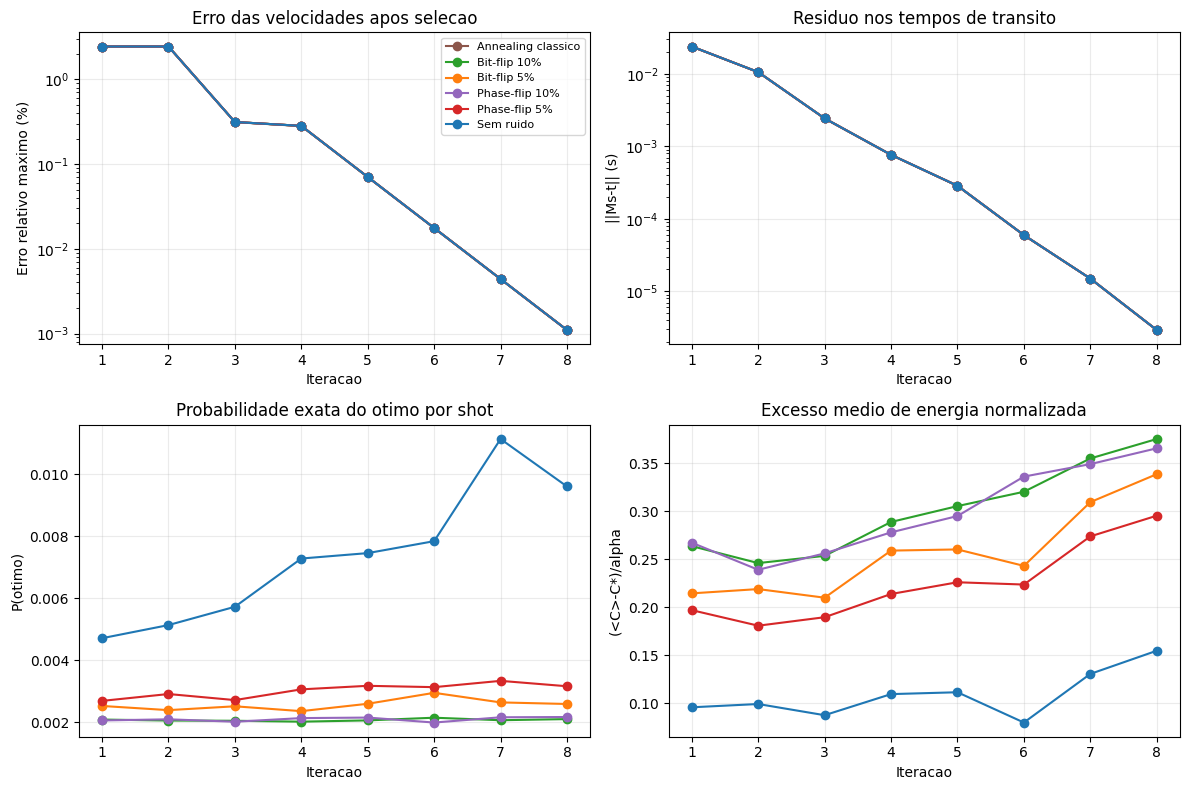

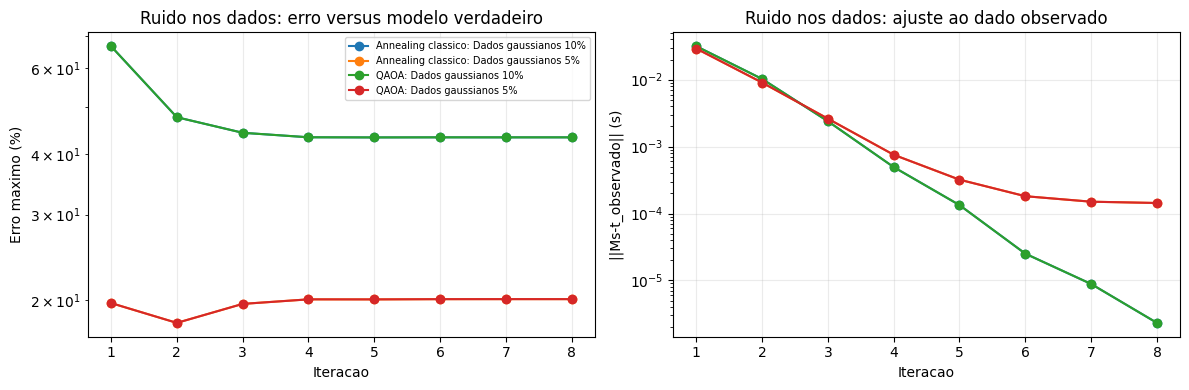

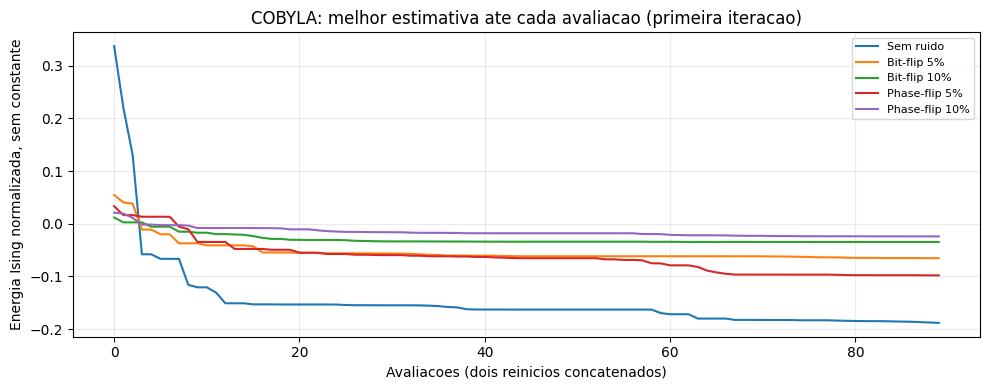

In [ ]:
plot_results(df);
plot_optimizer(traces);

In [ ]:
primeira = df[(df.method=='QAOA') & (df.experiment=='Portas') & (df.iteration==1)]
display(primeira.groupby('scenario')[['p_opt','predicted_success_128','predicted_success_4096','mean_normalized_excess']].mean())
print('Referencia uniforme, 128 amostras:', 1-(1-1/512)**128)
print('Referencia uniforme, 4096 amostras:', 1-(1-1/512)**4096)

,p_opt,predicted_success_128,predicted_success_4096,mean_normalized_excess
scenario,,,,
Bit-flip 10%,0.002091,0.235078,0.999811,0.263821
Bit-flip 5%,0.002530,0.276826,0.999965,0.214614
Phase-flip 10%,0.002062,0.232127,0.999769,0.267408
Phase-flip 5%,0.002693,0.291883,0.999983,0.197104
Sem ruido,0.004715,0.452956,1.000000,0.095877


Referencia uniforme, 128 amostras: 0.22138957850710417
Referencia uniforme, 4096 amostras: 0.9996671513538756


## Interpretação dos resultados

Leia a tabela de erro junto com a probabilidade do ótimo e a energia média.
Uma taxa de acerto alta do **melhor de 4096** não implica que a distribuição
quântica seja boa: até a distribuição uniforme em 512 estados inclui um ótimo
fixo com probabilidade aproximadamente 99,97% nesse orçamento.

Nos dados com ruído, resíduo pequeno pode coexistir com erro maior das velocidades.
Há três equações para três incógnitas e nenhuma regularização; portanto a solução
pode ajustar o dado perturbado sem recuperar o modelo verdadeiro.

COBYLA não garante o ótimo global dos ângulos. Três seeds permitem uma comparação
descritiva, não uma conclusão estatística universal. Os tempos medem simulação
clássica e incluem auditoria; não são tempos de um computador quântico.

**Conclusão a avaliar:** os canais alteram a distribuição de saída e a qualidade
das amostras. O refinamento recursivo e a seleção entre muitas medições podem
preservar a precisão final deste exemplo pequeno. Nenhum resultado demonstra
vantagem quântica sobre a solução clássica direta.

Referências: [Qiskit Aer — modelos de ruído](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html),
[EstimatorV2](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.primitives.EstimatorV2.html),
[D-Wave — algoritmos clássicos](https://docs.dwavequantum.com/en/latest/ocean/api_ref_samplers/),
[Souza et al. (2022)](https://doi.org/10.3389/fphy.2021.748285).
